# Notebook 15: Stabilizing Non-IID Drift with FedProx Proximal Regularization ($\mu = 0.01$)

## 1. Proximal Objective
$$h_k(\mathbf{w}; \mathbf{w}^t) = \mathcal{L}_{\text{BPR}, k}(\mathbf{w}) + \frac{\mu}{2} \|\mathbf{w} - \mathbf{w}^t\|_2^2$$
By tethering local client updates toward the broadcast global parameters $\mathbf{w}^t$, FedProx suppresses orthogonal drift across specialized readers.

In [1]:
import os, sys, json, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Resolve repository root deterministically from ml/notebooks/
REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

DATA_DIR = os.path.join(REPO_ROOT, "ml", "data", "processed")
ARTIFACTS_DIR = os.path.join(REPO_ROOT, "ml", "artifacts")
VIZ_DIR = os.path.join(REPO_ROOT, "ml", "visualizations")
plt.rcParams["figure.dpi"] = 110
with open(os.path.join(ARTIFACTS_DIR, "federated_benchmark.json"), "r") as f:
    bench = json.load(f)

df_avg = pd.DataFrame(bench["fedavg_history"])
df_prox = pd.DataFrame(bench["fedprox_history"])

lift_ndcg = (bench["fedprox_non_iid"]["ndcg10"] - bench["fedavg_non_iid"]["ndcg10"]) / bench["fedavg_non_iid"]["ndcg10"] * 100
gini_drop = (bench["fedavg_non_iid"]["gini_inequality"] - bench["fedprox_non_iid"]["gini_inequality"]) / bench["fedavg_non_iid"]["gini_inequality"] * 100

comp = pd.DataFrame([
    {"Metric": "Final NDCG@10", "FedAvg": f"{bench['fedavg_non_iid']['ndcg10']:.4f}", "FedProx (mu=0.01)": f"{bench['fedprox_non_iid']['ndcg10']:.4f}", "Delta": f"+{lift_ndcg:.1f}%"},
    {"Metric": "Final HR@10", "FedAvg": f"{bench['fedavg_non_iid']['hr10']:.4f}", "FedProx (mu=0.01)": f"{bench['fedprox_non_iid']['hr10']:.4f}", "Delta": f"+{(bench['fedprox_non_iid']['hr10']-bench['fedavg_non_iid']['hr10'])*100:.2f} pp"},
    {"Metric": "Final MRR", "FedAvg": f"{bench['fedavg_non_iid']['mrr']:.4f}", "FedProx (mu=0.01)": f"{bench['fedprox_non_iid']['mrr']:.4f}", "Delta": f"+{(bench['fedprox_non_iid']['mrr']-bench['fedavg_non_iid']['mrr']):.4f}"},
    {"Metric": "Client Gini Index", "FedAvg": f"{bench['fedavg_non_iid']['gini_inequality']:.4f}", "FedProx (mu=0.01)": f"{bench['fedprox_non_iid']['gini_inequality']:.4f}", "Delta": f"-{gini_drop:.1f}% (Fairer)"},
])
print(comp.to_string(index=False))

           Metric FedAvg FedProx (mu=0.01)          Delta
    Final NDCG@10 0.0500            0.0742         +48.4%
      Final HR@10 0.1232            0.1551       +3.19 pp
        Final MRR 0.0615            0.0825        +0.0210
Client Gini Index 0.3528            0.3230 -8.4% (Fairer)


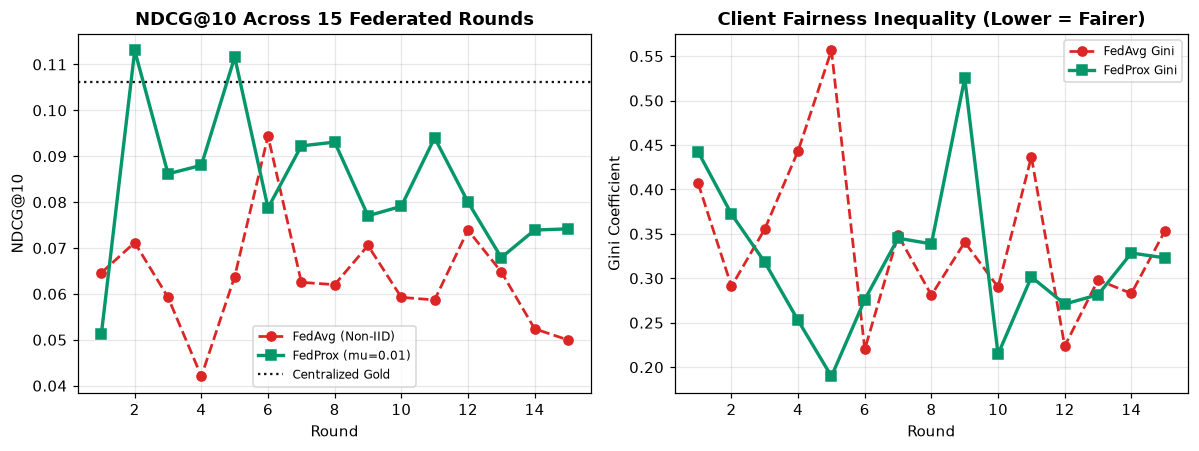

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].plot(df_avg["round"], df_avg["ndcg10"], "o--", color="#dc2626", lw=1.8, label="FedAvg (Non-IID)")
axes[0].plot(df_prox["round"], df_prox["ndcg10"], "s-", color="#059669", lw=2.2, label="FedProx (mu=0.01)")
axes[0].axhline(bench["centralized_baseline"]["ndcg10"], color="#111110", linestyle=":", label="Centralized Gold")
axes[0].set_title("NDCG@10 Across 15 Federated Rounds", fontweight="bold")
axes[0].set_xlabel("Round")
axes[0].set_ylabel("NDCG@10")
axes[0].grid(alpha=0.3)
axes[0].legend(fontsize=8)

axes[1].plot(df_avg["round"], df_avg["gini"], "o--", color="#dc2626", lw=1.8, label="FedAvg Gini")
axes[1].plot(df_prox["round"], df_prox["gini"], "s-", color="#059669", lw=2.2, label="FedProx Gini")
axes[1].set_title("Client Fairness Inequality (Lower = Fairer)", fontweight="bold")
axes[1].set_xlabel("Round")
axes[1].set_ylabel("Gini Coefficient")
axes[1].grid(alpha=0.3)
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()